In [8]:
import numpy as np 
import matplotlib.pyplot as plt


from sdp import optimal_recovery
from codes import leung_isometry
from channels import noisy_kraus_operator
from recovery import baseline_recovery_kraus
from petz import completed_petz_kraus
from fidelity import entanglement_fidelity

In [9]:
GAMMAS = [0, 0.05, 0.1, 0.2, 0.3]

V =leung_isometry()
bits = [format(i, '04b') for i in range(16)]
noisy_kraus = lambda gamma : [noisy_kraus_operator(bit, gamma) for bit in bits]
noisy_encoding_kraus = lambda gamma : [N@V for N in noisy_kraus(gamma)]
R = baseline_recovery_kraus()
R_til = lambda gamma : completed_petz_kraus(np.eye(2)/2 , gamma)
baseline_recov = lambda gamma : [r@E for r in R for E in noisy_encoding_kraus(gamma)]
petz_recove = lambda gamma : [r_til@E for r_til in R_til(gamma) for E in noisy_encoding_kraus(gamma)]

fidelity_baseline = [entanglement_fidelity(baseline_recov(gamma)) for gamma in GAMMAS]
fidelity_recov = [entanglement_fidelity(petz_recove(gamma)) for gamma in GAMMAS]
fidelity_opti = [optimal_recovery(gamma)[0] for gamma in GAMMAS]

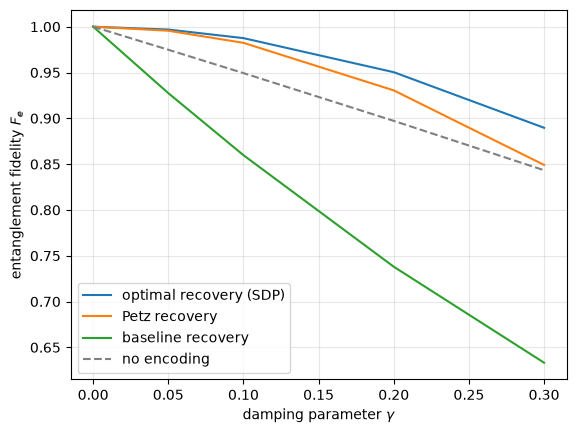

In [10]:

f_none = (1 + np.sqrt(1 - np.array(GAMMAS)))**2 / 4

plt.plot(GAMMAS, fidelity_opti, label="optimal recovery (SDP)")
plt.plot(GAMMAS, fidelity_recov, label="Petz recovery")
plt.plot(GAMMAS, fidelity_baseline, label="baseline recovery")
plt.plot(GAMMAS, f_none, "--", color="gray", label="no encoding")
plt.xlabel(r"damping parameter $\gamma$")
plt.ylabel(r"entanglement fidelity $F_e$")
plt.legend()
plt.grid(alpha=0.3)
plt.show()